In [1]:
import os
import pandas as pd

from dotenv import load_dotenv
from sqlalchemy import create_engine

In [3]:
load_dotenv()
engine = create_engine(os.getenv("DATABASE_URL"))

In [4]:
query = """ 
WITH churn_windows AS (
    SELECT
        d.customer_id,
        d.cutoff_date,
        w.window_name,
        w.window_interval

    FROM churn_model_dataset d

    CROSS JOIN (
        VALUES
            ('1 Week', INTERVAL '7 days'),
            ('1 Month', INTERVAL '1 month'),
            ('3 Months', INTERVAL '3 months'),
            ('6 Months', INTERVAL '6 months'),
            ('12 Months', INTERVAL '12 months')
    ) AS w(window_name, window_interval)
),

churn_labels AS (
    SELECT
        cw.window_name,
        cw.customer_id,
        cw.cutoff_date,

        CASE
            WHEN COUNT(a.customer_id) = 0 THEN 1
            ELSE 0
        END AS churned

    FROM churn_windows cw

    LEFT JOIN customer_daily_activity a
        ON a.customer_id = cw.customer_id
        AND a.transaction_date > cw.cutoff_date
        AND a.transaction_date <=
            cw.cutoff_date + cw.window_interval

    GROUP BY
        cw.window_name,
        cw.customer_id,
        cw.cutoff_date
)

SELECT
    window_name,
    COUNT(*) AS total_customers,

    SUM(churned) AS churned_customers,

    ROUND(
        AVG(churned::NUMERIC) * 100,
        2
    ) AS churn_percentage,

    ROUND(
        (1 - AVG(churned::NUMERIC)) * 100,
        2
    ) AS retained_percentage

FROM churn_labels

GROUP BY window_name

ORDER BY
    CASE window_name
        WHEN '1 Week' THEN 1
        WHEN '1 Month' THEN 2
        WHEN '3 Months' THEN 3
        WHEN '6 Months' THEN 4
        WHEN '12 Months' THEN 5
    END;
"""

churn_proportions = pd.read_sql(query, engine)

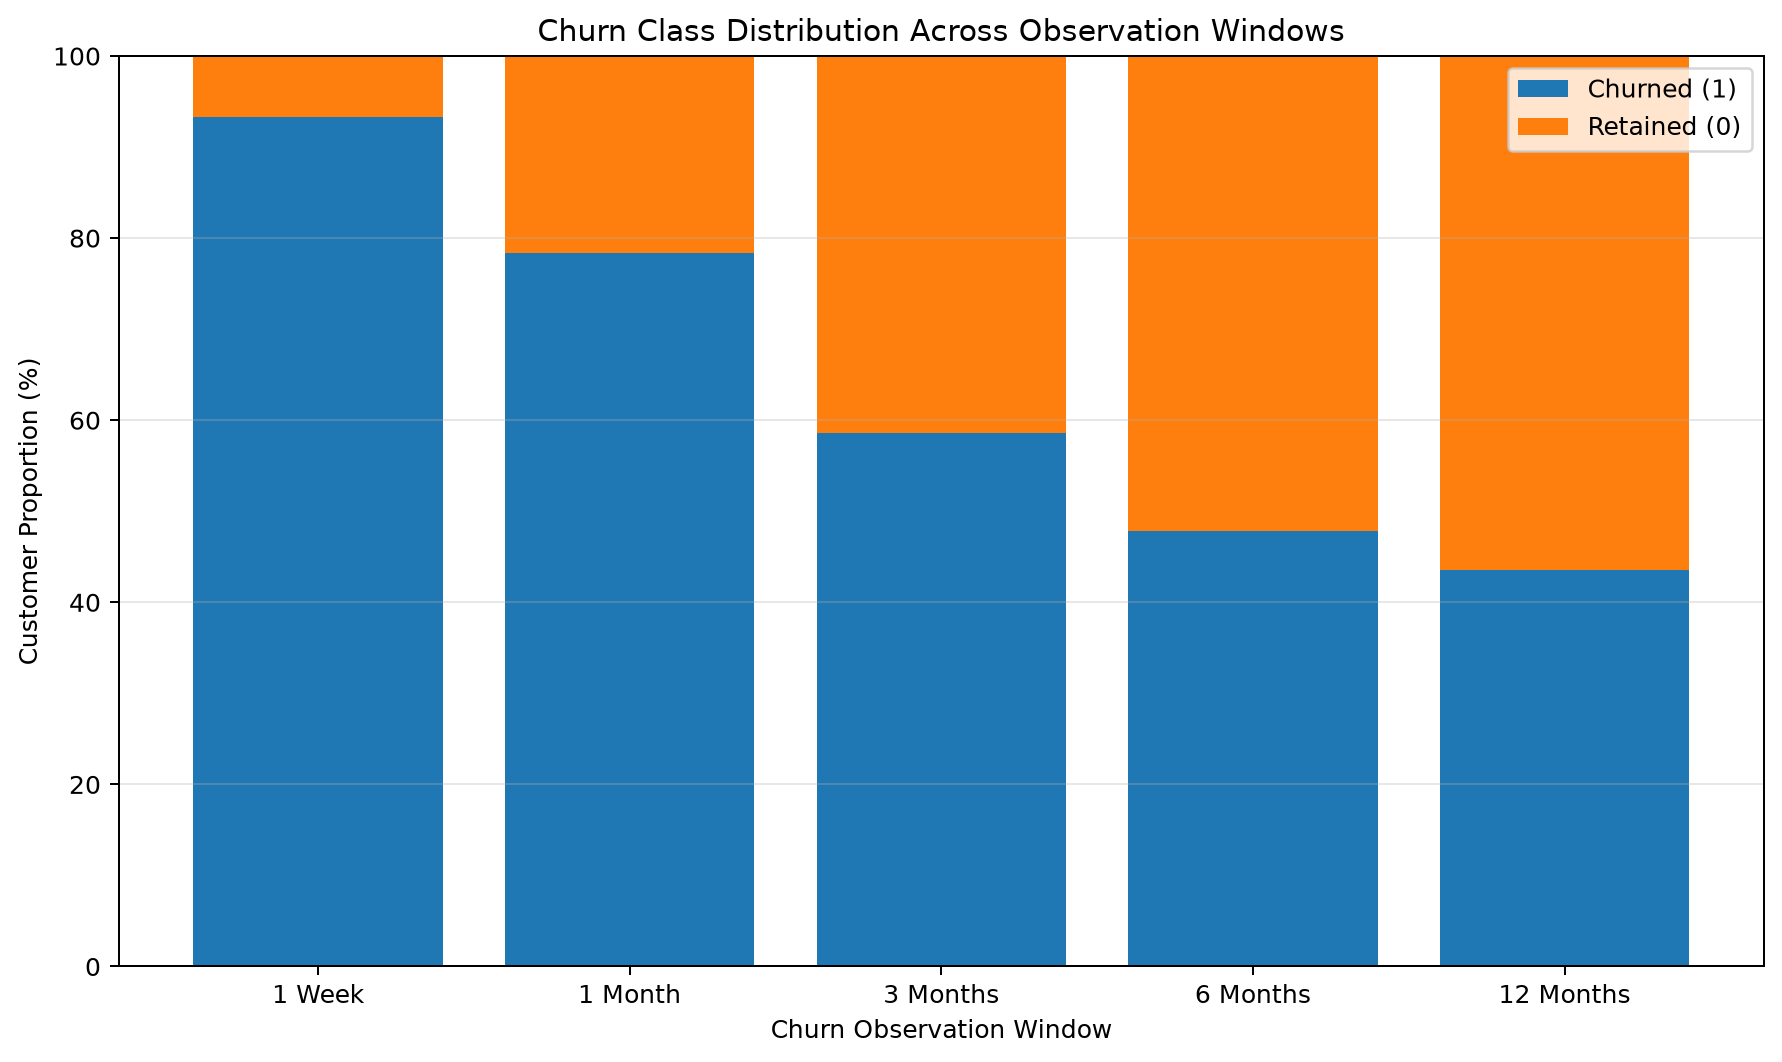

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    churn_proportions["window_name"],
    churn_proportions["churn_percentage"],
    label="Churned (1)"
)

plt.bar(
    churn_proportions["window_name"],
    churn_proportions["retained_percentage"],
    bottom=churn_proportions["churn_percentage"],
    label="Retained (0)"
)

plt.title("Churn Class Distribution Across Observation Windows")
plt.xlabel("Churn Observation Window")
plt.ylabel("Customer Proportion (%)")

plt.ylim(0, 100)
plt.legend(loc="upper right")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()